# SQLite Database Project: Online Grocery Market Basket Analysis

## 1. Requirements and configuration

In [1]:
from pathlib import Path
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
rng = np.random.default_rng(SEED)
SOURCE_FILENAME = "instacart_market_basket_analysis.parquet"
SOURCE_CANDIDATES = [Path.cwd() / SOURCE_FILENAME, Path('/mnt/data') / SOURCE_FILENAME]
SOURCE_PATH = next((p for p in SOURCE_CANDIDATES if p.is_file()), None)
DB_PATH = Path.cwd() / "online_grocery_market_basket.sqlite"
SCHEMA_PATH = Path.cwd() / "online_grocery_schema.sql"
FEATURES_PATH = Path.cwd() / "online_grocery_ml_features.csv"
MAX_SOURCE_ORDERS = 4_000

print('Source parquet:', SOURCE_PATH if SOURCE_PATH else 'not found')
print('SQLite destination:', DB_PATH)

Source parquet: /content/instacart_market_basket_analysis.parquet
SQLite destination: /content/online_grocery_market_basket.sqlite


## 2. Read and clean the source, or produce an explicitly labeled fallback

In [2]:
def synthetic_baskets(num_orders=4_000, num_products=160):
    rows = []
    choices = np.arange(1, num_products + 1, dtype=np.int64)
    popularity = np.arange(1, num_products + 1, dtype=float) ** (-0.7)
    popularity /= popularity.sum()
    for order_id in range(1, num_orders + 1):
        size = int(rng.integers(4, 16))
        products = list(map(int, rng.choice(choices, size=size, replace=False, p=popularity)))
        # A recurrent pair creates a visible, testable market-basket relationship.
        if rng.random() < 0.24:
            products = list(dict.fromkeys(products + [1, 2]))
        rng.shuffle(products)
        for position, product_id in enumerate(products, start=1):
            reordered = int(rng.random() < (0.42 if product_id < 25 else 0.21))
            rows.append((order_id, product_id, position, reordered))
    return pd.DataFrame(rows, columns=['order_id', 'product_id',
                                       'add_to_cart_order', 'reordered'])

source_mode = 'fully_synthetic_fallback'
has_parquet_engine = False
try:
    import pyarrow
    has_parquet_engine = True
except ImportError:
    try:
        !pip install fastparquet -q
        import fastparquet
        has_parquet_engine = True
    except ImportError:
        pass

if SOURCE_PATH is None:
    print('No Parquet file detected; generating fully synthetic order lines.')
    baskets = synthetic_baskets()
elif not has_parquet_engine:
    print('Parquet engine unavailable (pyarrow or fastparquet not found). Generating synthetic order lines.')
    baskets = synthetic_baskets()
else:
    try:
        raw = pd.read_parquet(SOURCE_PATH)
    except ImportError as exc:
        warnings.warn('Parquet engine unavailable (install pyarrow to use the uploaded data). '
                      'Generating clearly labeled synthetic order lines. ' + str(exc), stacklevel=1)
        baskets = synthetic_baskets()
    else:
        raw.columns = [str(c).strip().lower() for c in raw.columns]
        needed = ['order_id', 'product_id', 'add_to_cart_order', 'reordered']
        missing = set(needed) - set(raw.columns)
        if missing:
            raise ValueError(f'Parquet data is missing required fields: {sorted(missing)}')
        baskets = raw[needed].copy()
        for column in needed:
            baskets[column] = pd.to_numeric(baskets[column], errors='coerce')
        baskets = baskets.dropna(subset=needed)
        baskets = baskets.loc[(baskets.order_id > 0) & (baskets.product_id > 0) &
                              (baskets.add_to_cart_order > 0) &
                              baskets.reordered.isin([0, 1])].copy()
        baskets[needed] = baskets[needed].astype('int64')
        baskets = baskets.drop_duplicates(subset=['order_id', 'product_id'])
        baskets = baskets.drop_duplicates(subset=['order_id', 'add_to_cart_order'])
        ids = baskets['order_id'].drop_duplicates().to_numpy()
        if len(ids) > MAX_SOURCE_ORDERS:
            ids = rng.choice(ids, size=MAX_SOURCE_ORDERS, replace=False)
            baskets = baskets.loc[baskets.order_id.isin(ids)].copy()
        if baskets['order_id'].nunique() < 1_000 or len(baskets) < 1_000:
            raise ValueError('Source has fewer than 1,000 usable records/orders: '
                             'provide a larger Parquet dataset or use synthetic mode.')
        baskets = baskets.sort_values(['order_id', 'add_to_cart_order']).reset_index(drop=True)
        source_mode = 'sampled_uploaded_parquet'

assert baskets['order_id'].nunique() >= 1_000
assert len(baskets) >= 1_000
assert not baskets.duplicated(['order_id', 'product_id']).any()
assert not baskets.duplicated(['order_id', 'add_to_cart_order']).any()
print('Mode:', source_mode)
print('Orders:', baskets.order_id.nunique(), '| Order-item records:', len(baskets),
      '| Distinct products:', baskets.product_id.nunique())
display(baskets.head(8))

Mode: sampled_uploaded_parquet
Orders: 4000 | Order-item records: 41768 | Distinct products: 11121


,order_id,product_id,add_to_cart_order,reordered
0,4726,24571,1,1
1,4726,49683,2,1
2,4726,40516,3,0
3,4726,48182,4,1
4,4726,43295,5,0
5,4726,34287,6,0
6,4726,2361,7,0
7,4726,4671,8,0


## 3. Generate relational dimension and transaction data

In [3]:
CATEGORIES = {
    'Produce': ['Organic Bananas', 'Avocado', 'Baby Spinach', 'Fuji Apples', 'Strawberries'],
    'Dairy & Eggs': ['Whole Milk', 'Greek Yogurt', 'Free-range Eggs', 'Cheddar Cheese', 'Butter'],
    'Bakery': ['Wholegrain Bread', 'Bagels', 'Croissants', 'Tortillas', 'Muffins'],
    'Pantry': ['Olive Oil', 'Basmati Rice', 'Pasta', 'Canned Chickpeas', 'Oat Cereal'],
    'Beverages': ['Spring Water', 'Orange Juice', 'Green Tea', 'Coffee Beans', 'Sparkling Water'],
    'Frozen': ['Frozen Peas', 'Frozen Berries', 'Frozen Pizza', 'Ice Cream', 'Vegetable Mix'],
    'Snacks': ['Mixed Nuts', 'Potato Chips', 'Granola Bars', 'Crackers', 'Popcorn'],
    'Household': ['Dish Soap', 'Laundry Detergent', 'Paper Towels', 'Tissues', 'Sponges'],
}
CATEGORY_BASE_PRICE = {
    'Produce': 3.2, 'Dairy & Eggs': 4.9, 'Bakery': 3.8, 'Pantry': 6.2,
    'Beverages': 4.5, 'Frozen': 6.7, 'Snacks': 3.8, 'Household': 8.8,
}
CITIES = ['Chicago', 'New York', 'Seattle', 'Austin', 'Boston', 'Denver']
CITY_AVG_TEMP = {'Chicago': 12, 'New York': 15, 'Seattle': 12,
                 'Austin': 22, 'Boston': 13, 'Denver': 11}
TIERS = ['Bronze', 'Silver', 'Gold', 'Platinum']

# Product descriptions are synthetic; don't infer original names from source product IDs.
product_ids = sorted(map(int, baskets.product_id.unique()))
cat_names = list(CATEGORIES)
product_rows = []
for product_id in product_ids:
    category = cat_names[(product_id * 7 + product_id // 11) % len(cat_names)]
    options = CATEGORIES[category]
    base_name = options[(product_id // len(cat_names)) % len(options)]
    base_price = CATEGORY_BASE_PRICE[category]
    price = round(float(np.clip(rng.lognormal(np.log(base_price), 0.32), 0.75, 49.99)), 2)
    storage = 'Frozen' if category == 'Frozen' else ('Chilled' if category == 'Dairy & Eggs' else 'Ambient')
    product_rows.append((product_id, f'{base_name} [synthetic SKU {product_id}]',
                         category, storage, price))
products = pd.DataFrame(product_rows, columns=['product_id', 'product_name', 'category',
                                               'storage_type', 'unit_price'])

# A sampled source can contain many orders but no linked customer identifiers.
num_customers = max(1_000, int(baskets.order_id.nunique() * 0.32))
customers = pd.DataFrame({
    'customer_id': np.arange(1, num_customers + 1, dtype=int),
    'city': rng.choice(CITIES, size=num_customers, p=[.20,.22,.17,.17,.13,.11]),
    'membership_tier': rng.choice(TIERS, size=num_customers, p=[.45,.30,.18,.07]),
    'signup_date': (pd.Timestamp('2022-01-01') + pd.to_timedelta(
        rng.integers(0, 365*3, size=num_customers), unit='D')).strftime('%Y-%m-%d'),
    'loyalty_points': rng.integers(0, 3001, size=num_customers),
})

# One order belongs to one customer. Dates, weather and payments are synthetic.
order_ids = sorted(map(int, baskets.order_id.unique()))
order_count = len(order_ids)
customer_lookup = customers.set_index('customer_id')
selected_customers = rng.choice(customers.customer_id.to_numpy(), size=order_count)
selected_cities = customer_lookup.loc[selected_customers, 'city'].to_numpy()
selected_tiers = customer_lookup.loc[selected_customers, 'membership_tier'].to_numpy()
dates = pd.Timestamp('2025-01-01') + pd.to_timedelta(
    rng.integers(0, 365 + 273, size=order_count), unit='D')  # through September 2026
hours = rng.choice(np.arange(7, 23), size=order_count,
                   p=np.array([2,2,3,4,5,6,7,8,9,10,10,9,8,7,6,4], dtype=float) / 100)
minutes = rng.integers(0, 60, size=order_count)
timestamps = dates + pd.to_timedelta(hours, unit='h') + pd.to_timedelta(minutes, unit='m')
seasonal = 9 * np.cos((dates.month.to_numpy() - 7) * 2*np.pi / 12)
temps = [round(float(np.clip(CITY_AVG_TEMP[city] + season + rng.normal(0, 3.5), -22, 45)), 1)
         for city, season in zip(selected_cities, seasonal)]
priority = rng.choice([1,2,3], size=order_count, p=[.68,.25,.07])
payments = rng.choice(['Card', 'Digital Wallet', 'Gift Card'],
                      size=order_count, p=[.69,.27,.04])
statuses = rng.choice(['Delivered', 'Picked Up'], size=order_count, p=[.92,.08])

orders = pd.DataFrame({
    'order_id': order_ids,
    'customer_id': selected_customers.astype(int),
    'order_timestamp': timestamps.strftime('%Y-%m-%d %H:%M:%S'),
    'delivery_priority': priority.astype(int),
    'delivery_temp_c': temps,
    'payment_method': payments,
    'fulfillment_status': statuses,
})

order_items = baskets.copy()
order_items['quantity'] = rng.choice([1,2,3,4], size=len(order_items), p=[.73,.19,.065,.015])
price_lookup = products.set_index('product_id')['unit_price']
order_items['unit_price'] = (order_items['product_id'].map(price_lookup).to_numpy() *
                             rng.uniform(.95, 1.05, size=len(order_items))).round(2)
order_items['line_total'] = (order_items['quantity'] * order_items['unit_price']).round(2)

summary = order_items.groupby('order_id').agg(
    item_count=('quantity', 'sum'), subtotal=('line_total', 'sum')).reset_index()
summary['subtotal'] = summary['subtotal'].round(2)
orders = orders.merge(summary, on='order_id', how='left', validate='one_to_one')
orders['delivery_fee'] = [0.0 if (status == 'Picked Up' or tier in ['Gold','Platinum'])
                          else (6.99 if level == 3 else 4.99 if level == 2 else 2.99)
                          for tier, status, level in zip(selected_tiers, orders.fulfillment_status,
                                                         orders.delivery_priority)]
orders['order_total'] = (orders['subtotal'] + orders['delivery_fee']).round(2)

# Order-item column order matches the SQLite INSERT statement.
order_items = order_items[['order_id','product_id','add_to_cart_order',
                           'quantity','unit_price','line_total','reordered']]
orders = orders[['order_id','customer_id','order_timestamp','delivery_priority',
                 'delivery_temp_c','payment_method','fulfillment_status','subtotal',
                 'delivery_fee','order_total','item_count']]

assert len(orders) >= 1000 and len(order_items) >= 1000
assert orders.notna().all().all() and order_items.notna().all().all()
print('Customers:', len(customers), '| Products:', len(products),
      '| Orders:', len(orders), '| Order items:', len(order_items))
display(orders.head(5))

Customers: 1280 | Products: 11121 | Orders: 4000 | Order items: 41768


,order_id,customer_id,order_timestamp,delivery_priority,delivery_temp_c,payment_method,fulfillment_status,subtotal,delivery_fee,order_total,item_count
0,4726,1182,2026-01-18 08:17:00,1,1.4,Digital Wallet,Delivered,106.46,0.00,106.46,23
1,5619,402,2025-07-15 20:13:00,1,19.6,Card,Delivered,19.82,2.99,22.81,4
2,5836,358,2026-04-03 22:42:00,1,16.4,Card,Delivered,122.50,2.99,125.49,26
3,6443,515,2026-02-27 21:06:00,1,9.2,Card,Delivered,34.38,0.00,34.38,9
4,7697,620,2025-05-11 17:32:00,1,19.6,Digital Wallet,Delivered,53.34,0.00,53.34,11


## 4. Design the SQLite schema and enforce referential integrity

In [4]:
SCHEMA_SQL = """
CREATE TABLE customers (
    customer_id      INTEGER PRIMARY KEY,
    city             TEXT NOT NULL,
    membership_tier  TEXT NOT NULL CHECK (membership_tier IN ('Bronze','Silver','Gold','Platinum')),
    signup_date      TEXT NOT NULL,
    loyalty_points   INTEGER NOT NULL CHECK (loyalty_points >= 0)
);
CREATE TABLE products (
    product_id       INTEGER PRIMARY KEY,
    product_name     TEXT NOT NULL,
    category         TEXT NOT NULL,
    storage_type     TEXT NOT NULL CHECK (storage_type IN ('Ambient','Chilled','Frozen')),
    unit_price       REAL NOT NULL CHECK (unit_price > 0)
);
CREATE TABLE orders (
    order_id           INTEGER PRIMARY KEY,
    customer_id        INTEGER NOT NULL,
    order_timestamp    TEXT NOT NULL,
    delivery_priority  INTEGER NOT NULL CHECK (delivery_priority BETWEEN 1 AND 3),
    delivery_temp_c    REAL NOT NULL CHECK (delivery_temp_c BETWEEN -40 AND 55),
    payment_method     TEXT NOT NULL CHECK (payment_method IN ('Card','Digital Wallet','Gift Card')),
    fulfillment_status TEXT NOT NULL CHECK (fulfillment_status IN ('Delivered','Picked Up')),
    subtotal           REAL NOT NULL CHECK (subtotal >= 0),
    delivery_fee       REAL NOT NULL CHECK (delivery_fee >= 0),
    order_total        REAL NOT NULL CHECK (order_total >= 0),
    item_count         INTEGER NOT NULL CHECK (item_count >= 1),
    CHECK (ABS(order_total - (subtotal + delivery_fee)) < 0.011),
    FOREIGN KEY (customer_id) REFERENCES customers(customer_id)
);
CREATE TABLE order_items (
    order_id          INTEGER NOT NULL,
    product_id        INTEGER NOT NULL,
    add_to_cart_order INTEGER NOT NULL CHECK (add_to_cart_order >= 1),
    quantity          INTEGER NOT NULL CHECK (quantity >= 1),
    unit_price        REAL NOT NULL CHECK (unit_price > 0),
    line_total        REAL NOT NULL CHECK (line_total >= 0),
    reordered         INTEGER NOT NULL CHECK (reordered IN (0,1)),
    PRIMARY KEY (order_id, product_id),
    UNIQUE (order_id, add_to_cart_order),
    CHECK (ABS(line_total - quantity * unit_price) < 0.011),
    FOREIGN KEY (order_id) REFERENCES orders(order_id),
    FOREIGN KEY (product_id) REFERENCES products(product_id)
) WITHOUT ROWID;
CREATE TABLE data_provenance (
    source_id INTEGER PRIMARY KEY,
    source_mode TEXT NOT NULL,
    source_filename TEXT,
    origin_notes TEXT NOT NULL,
    sampled_order_count INTEGER NOT NULL,
    sampled_line_count INTEGER NOT NULL
);
CREATE INDEX idx_orders_customer ON orders(customer_id);
CREATE INDEX idx_orders_date ON orders(order_timestamp);
CREATE INDEX idx_items_product ON order_items(product_id);
CREATE INDEX idx_products_category ON products(category);
"""

# Idempotent rebuild for an educational assignment.
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute('PRAGMA foreign_keys = ON')
assert conn.execute('PRAGMA foreign_keys').fetchone()[0] == 1
conn.executescript(SCHEMA_SQL)

with conn:  # transaction: all changes commit together, or roll back on exception
    conn.executemany('INSERT INTO customers VALUES (?,?,?,?,?)',
                     customers.itertuples(index=False, name=None))
    conn.executemany('INSERT INTO products VALUES (?,?,?,?,?)',
                     products.itertuples(index=False, name=None))
    conn.executemany('INSERT INTO orders VALUES (?,?,?,?,?,?,?,?,?,?,?)',
                     orders.itertuples(index=False, name=None))
    conn.executemany('INSERT INTO order_items VALUES (?,?,?,?,?,?,?)',
                     order_items.itertuples(index=False, name=None))
    origin = ('Original order-item identifiers, cart positions and reorder flags sampled '
              'from uploaded Parquet; other fields synthesized.'
              if source_mode == 'sampled_uploaded_parquet' else
              'All fields synthesized; Parquet was missing or no Parquet reader was installed.')
    conn.execute('INSERT INTO data_provenance VALUES (?,?,?,?,?,?)',
                 (1, source_mode, str(SOURCE_PATH) if SOURCE_PATH else None,
                  origin, len(orders), len(order_items)))

SCHEMA_PATH.write_text(SCHEMA_SQL, encoding='utf-8')
print('SQLite database created:', DB_PATH, f'({DB_PATH.stat().st_size / 1_048_576:.2f} MiB)')
print('Schema written:', SCHEMA_PATH)

SQLite database created: /content/online_grocery_market_basket.sqlite (4.10 MiB)
Schema written: /content/online_grocery_schema.sql


## 5. Verify the database (row counts, keys, constraints, data integrity)

In [5]:
table_counts = pd.read_sql_query("""
SELECT name AS table_name,
       (SELECT COUNT(*) FROM sqlite_master AS s2 WHERE s2.name = s1.name) AS schema_entries
FROM sqlite_master AS s1
WHERE type='table' ORDER BY name;
""", conn)
counts = pd.DataFrame([(table, conn.execute(f'SELECT COUNT(*) FROM {table}').fetchone()[0])
                       for table in ['customers','products','orders','order_items','data_provenance']],
                      columns=['table_name','number_of_rows'])
display(counts)
assert counts.set_index('table_name').loc['orders','number_of_rows'] >= 1000
assert counts.set_index('table_name').loc['order_items','number_of_rows'] >= 1000
assert conn.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
assert conn.execute('PRAGMA foreign_key_check').fetchall() == []

mismatches = conn.execute("""
SELECT COUNT(*) FROM orders AS o LEFT JOIN (
    SELECT order_id, SUM(quantity) AS n_items, SUM(line_total) AS sub
    FROM order_items GROUP BY order_id
) AS b ON o.order_id = b.order_id
WHERE b.order_id IS NULL OR o.item_count <> b.n_items
   OR ABS(o.subtotal - b.sub) > 0.011;
""").fetchone()[0]
assert mismatches == 0, f'Order totals/count mismatches: {mismatches}'
assert conn.execute("SELECT COUNT(*) FROM order_items WHERE reordered NOT IN (0,1)").fetchone()[0] == 0

print('Integrity checks: PASS')
print('Composite primary-key columns:')
display(pd.read_sql_query('PRAGMA table_info(order_items)', conn)[['name','type','pk']])
print('Foreign keys:')
display(pd.read_sql_query('PRAGMA foreign_key_list(order_items)', conn)[['table','from','to']])
display(pd.read_sql_query('SELECT * FROM data_provenance', conn))

,table_name,number_of_rows
0,customers,1280
1,products,11121
2,orders,4000
3,order_items,41768
4,data_provenance,1


Integrity checks: PASS
Composite primary-key columns:


,name,type,pk
0,order_id,INTEGER,1
1,product_id,INTEGER,2
2,add_to_cart_order,INTEGER,0
3,quantity,INTEGER,0
4,unit_price,REAL,0
5,line_total,REAL,0
6,reordered,INTEGER,0


Foreign keys:


,table,from,to
0,products,product_id,product_id
1,orders,order_id,order_id


,source_id,source_mode,source_filename,origin_notes,sampled_order_count,sampled_line_count
0,1,sampled_uploaded_parquet,/content/instacart_market_basket_analysis.parquet,"Original order-item identifiers, cart position...",4000,41768


## 6. Extract insights using SQL

In [6]:
# JOIN orders -> customers -> order_items -> products; filter and order values.
sql_recent = """
SELECT o.order_id, o.order_timestamp, c.city, c.membership_tier,
       o.delivery_priority, p.category, p.product_name,
       i.quantity, i.line_total
FROM orders AS o
JOIN customers AS c ON o.customer_id = c.customer_id
JOIN order_items AS i ON o.order_id = i.order_id
JOIN products AS p ON i.product_id = p.product_id
WHERE o.order_total >= 25 AND o.delivery_priority >= 2
ORDER BY o.order_timestamp DESC, i.add_to_cart_order
LIMIT 10;
"""
display(pd.read_sql_query(sql_recent, conn))

sql_categories = """
SELECT p.category, COUNT(*) AS item_rows,
       SUM(i.quantity) AS units_sold,
       ROUND(SUM(i.line_total),2) AS revenue,
       ROUND(AVG(i.line_total),2) AS average_line_value
FROM order_items AS i JOIN products AS p ON p.product_id = i.product_id
GROUP BY p.category ORDER BY revenue DESC;
"""
category_sales = pd.read_sql_query(sql_categories, conn)
display(category_sales)

sql_tiers = """
SELECT c.membership_tier, COUNT(*) AS orders_placed,
       ROUND(AVG(o.order_total),2) AS average_order_value
FROM orders o JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.membership_tier
ORDER BY CASE c.membership_tier
    WHEN 'Bronze' THEN 1 WHEN 'Silver' THEN 2
    WHEN 'Gold' THEN 3 ELSE 4 END;
"""
display(pd.read_sql_query(sql_tiers, conn))

,order_id,order_timestamp,city,membership_tier,delivery_priority,category,product_name,quantity,line_total
0,1630111,2026-09-30 22:56:00,Chicago,Silver,2,Household,Laundry Detergent [synthetic SKU 24852],1,7.40
1,1630111,2026-09-30 22:56:00,Chicago,Silver,2,Bakery,Bagels [synthetic SKU 28571],1,11.93
2,1630111,2026-09-30 22:56:00,Chicago,Silver,2,Beverages,Green Tea [synthetic SKU 23623],1,5.33
3,1630111,2026-09-30 22:56:00,Chicago,Silver,2,Produce,Avocado [synthetic SKU 8448],1,6.93
4,1630111,2026-09-30 22:56:00,Chicago,Silver,2,Frozen,Frozen Pizza [synthetic SKU 35458],1,9.94
5,1630111,2026-09-30 22:56:00,Chicago,Silver,2,Snacks,Popcorn [synthetic SKU 10078],1,2.89
6,1630111,2026-09-30 22:56:00,Chicago,Silver,2,Household,Sponges [synthetic SKU 432],3,24.24
7,560939,2026-09-30 15:47:00,Seattle,Gold,2,Frozen,Frozen Berries [synthetic SKU 6532],2,24.90
8,560939,2026-09-30 15:47:00,Seattle,Gold,2,Household,Laundry Detergent [synthetic SKU 49131],1,9.47
9,560939,2026-09-30 15:47:00,Seattle,Gold,2,Household,Sponges [synthetic SKU 19677],1,8.68


,category,item_rows,units_sold,revenue,average_line_value
0,Household,5430,7405,67263.37,12.39
1,Frozen,5242,7124,49951.81,9.53
2,Pantry,4381,6005,39909.48,9.11
3,Beverages,5394,7343,34153.88,6.33
4,Snacks,5429,7447,29671.94,5.47
5,Bakery,5556,7536,29449.19,5.30
6,Produce,6306,8610,28639.88,4.54
7,Dairy & Eggs,4030,5489,28545.07,7.08


,membership_tier,orders_placed,average_order_value
0,Bronze,1768,80.04
1,Silver,1290,80.61
2,Gold,695,77.11
3,Platinum,247,77.39


## 7. SQL association rules: support, confidence and lift

In [7]:
sql_rules = """
WITH popular_products AS (
    SELECT product_id FROM order_items
    GROUP BY product_id ORDER BY COUNT(DISTINCT order_id) DESC LIMIT 100
),
items AS (
    SELECT order_id, product_id FROM order_items
    WHERE product_id IN (SELECT product_id FROM popular_products)
),
frequencies AS (
    SELECT product_id, COUNT(DISTINCT order_id) AS n_product_orders
    FROM items GROUP BY product_id
),
pairs AS (
    SELECT a.product_id AS antecedent, b.product_id AS consequent,
           COUNT(*) AS n_pair_orders
    FROM items a JOIN items b
      ON a.order_id = b.order_id AND a.product_id < b.product_id
    GROUP BY a.product_id, b.product_id
)
SELECT pa.product_name AS antecedent_product,
       pb.product_name AS consequent_product,
       pairs.n_pair_orders AS cooccurring_orders,
       ROUND(1.0*pairs.n_pair_orders/n.n_orders, 4) AS support,
       ROUND(1.0*pairs.n_pair_orders/fa.n_product_orders, 4) AS confidence,
       ROUND((1.0*pairs.n_pair_orders*n.n_orders)/
             (fa.n_product_orders*fb.n_product_orders), 4) AS lift
FROM pairs
JOIN frequencies fa ON pairs.antecedent = fa.product_id
JOIN frequencies fb ON pairs.consequent = fb.product_id
JOIN products pa ON pairs.antecedent = pa.product_id
JOIN products pb ON pairs.consequent = pb.product_id
CROSS JOIN (SELECT COUNT(*) AS n_orders FROM orders) n
WHERE pairs.n_pair_orders >= 4
ORDER BY lift DESC, cooccurring_orders DESC LIMIT 12;
"""
rules = pd.read_sql_query(sql_rules, conn)
display(rules)
print('Interpretation: association rules describe co-purchases, not cause and effect.')

,antecedent_product,consequent_product,cooccurring_orders,support,confidence,lift
0,Muffins [synthetic SKU 20114],Spring Water [synthetic SKU 28842],13,0.0032,0.1912,16.9935
1,Fuji Apples [synthetic SKU 21709],Green Tea [synthetic SKU 35221],12,0.0030,0.2264,14.3756
2,Tortillas [synthetic SKU 22825],Frozen Berries [synthetic SKU 39928],9,0.0022,0.1765,13.8408
3,Spring Water [synthetic SKU 28842],Organic Bananas [synthetic SKU 34126],8,0.0020,0.1778,10.4575
4,Green Tea [synthetic SKU 35221],Butter [synthetic SKU 44632],18,0.0045,0.2857,9.9379
5,Oat Cereal [synthetic SKU 31553],Laundry Detergent [synthetic SKU 33731],5,0.0013,0.1163,9.3023
6,Sponges [synthetic SKU 9839],Strawberries [synthetic SKU 22035],7,0.0018,0.1250,9.2593
7,Orange Juice [synthetic SKU 26369],Frozen Berries [synthetic SKU 39928],5,0.0013,0.1163,9.1199
8,Coffee Beans [synthetic SKU 10749],Baby Spinach [synthetic SKU 21938],15,0.0037,0.1899,9.0416
9,Crackers [synthetic SKU 31506],Organic Bananas [synthetic SKU 33000],6,0.0015,0.0968,8.7977


Interpretation: association rules describe co-purchases, not cause and effect.


## 8. Visualize and prepare data for onward processing

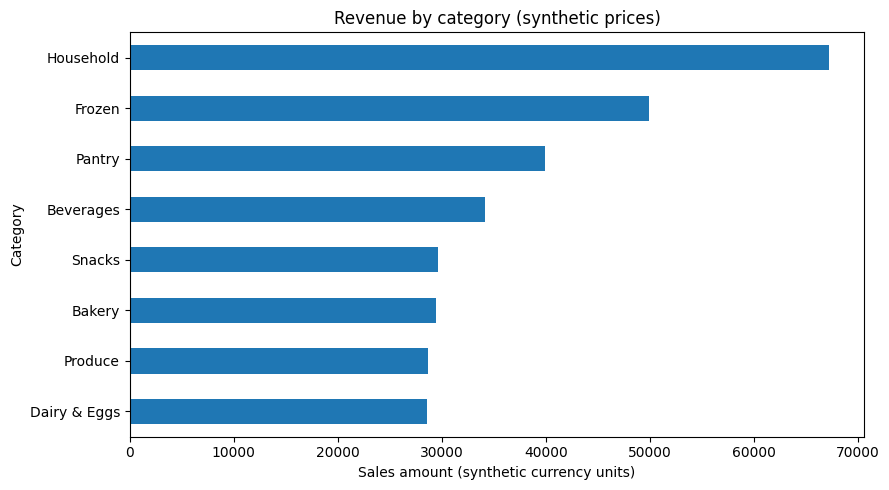

ML-ready data: (4000, 16) | CSV: /content/online_grocery_ml_features.csv


,order_id,delivery_priority,delivery_temp_c,item_count,order_total,share_reordered,membership_tier_rank,payment_method_Card,payment_method_Digital Wallet,payment_method_Gift Card,city_Austin,city_Boston,city_Chicago,city_Denver,city_New York,city_Seattle
0,4726,1,1.4,23,106.46,0.3333,4,0,1,0,0,0,1,0,0,0
1,5619,1,19.6,4,22.81,0.5000,1,1,0,0,0,0,1,0,0,0
2,5836,1,16.4,26,125.49,0.4118,1,1,0,0,0,0,0,0,1,0
3,6443,1,9.2,9,34.38,0.6667,4,1,0,0,0,0,0,0,1,0
4,7697,1,19.6,11,53.34,0.0000,3,0,1,0,0,0,0,0,0,1


In [8]:
ax = category_sales.sort_values('revenue').plot.barh(
    x='category', y='revenue', legend=False, figsize=(9,5), title='Revenue by category (synthetic prices)')
ax.set_xlabel('Sales amount (synthetic currency units)')
ax.set_ylabel('Category')
plt.tight_layout()
plt.show()

sql_features = """
SELECT o.order_id, o.delivery_priority, o.delivery_temp_c,
       o.payment_method, c.city, c.membership_tier,
       o.item_count, o.order_total,
       ROUND(1.0*SUM(i.reordered)/COUNT(*),4) AS share_reordered
FROM orders AS o
JOIN customers AS c ON o.customer_id = c.customer_id
JOIN order_items AS i ON o.order_id = i.order_id
GROUP BY o.order_id;
"""
features = pd.read_sql_query(sql_features, conn)
features['membership_tier_rank'] = features['membership_tier'].map(
    {'Bronze':1, 'Silver':2, 'Gold':3, 'Platinum':4})
assert not features.isna().any().any(), 'Handle missing data before ML export.'
prepared = pd.get_dummies(features.drop(columns='membership_tier'),
                          columns=['payment_method', 'city'], dtype=int)
assert len(prepared) == len(orders)
prepared.to_csv(FEATURES_PATH, index=False)
print('ML-ready data:', prepared.shape, '| CSV:', FEATURES_PATH)
display(prepared.head())

## 9. SQL vs NoSQL: why SQLite fits this assignment

In [9]:
import json
example_order = pd.read_sql_query('SELECT * FROM orders ORDER BY order_id LIMIT 1', conn).iloc[0]
example_lines = pd.read_sql_query(
    'SELECT product_id, quantity, unit_price, reordered FROM order_items WHERE order_id = ? '
    'ORDER BY add_to_cart_order LIMIT 4',
    conn, params=(int(example_order['order_id']),))
document_example = {
    'order_id': int(example_order['order_id']),
    'customer_id': int(example_order['customer_id']),
    'payment_method': str(example_order['payment_method']),
    'items': example_lines.to_dict(orient='records'),
}
print(json.dumps(document_example, indent=2))

{
  "order_id": 4726,
  "customer_id": 1182,
  "payment_method": "Digital Wallet",
  "items": [
    {
      "product_id": 24571,
      "quantity": 2,
      "unit_price": 2.13,
      "reordered": 1
    },
    {
      "product_id": 49683,
      "quantity": 1,
      "unit_price": 4.53,
      "reordered": 1
    },
    {
      "product_id": 40516,
      "quantity": 2,
      "unit_price": 7.22,
      "reordered": 0
    },
    {
      "product_id": 48182,
      "quantity": 1,
      "unit_price": 5.48,
      "reordered": 1
    }
  ]
}
